<a href="https://colab.research.google.com/github/psept77-star/CAPA_Effectiveness_Prediction/blob/main/CAPAEffectiveness_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


# Load the dataset
df = pd.read_csv('/content/sample_data/CAPA-dataset.csv')

# Encode categorical features with separate encoders
severity_encoder = LabelEncoder()
department_encoder = LabelEncoder()

df['Severity_encoded'] = severity_encoder.fit_transform(df['Severity'])
df['Department_encoded'] = department_encoder.fit_transform(df['Department'])

In [21]:
# 2. Model Selection
# Encode 'Overdue' column into numerical format with its own encoder
overdue_encoder = LabelEncoder()
df['Overdue_encoded'] = overdue_encoder.fit_transform(df['Overdue'])
x = df[['Severity_encoded', 'Department_encoded', 'Closure_Time_Days', 'Overdue_encoded']]
y = df['CAPA_Effective']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         2

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



In [12]:
# Model selection between Logistic regression, XGBoost and Random Forest
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

# Logistic Regression
logreg = LogisticRegression(random_state=42)
logreg.fit(x_train, y_train)
y_pred_logreg = logreg.predict(x_test)

# XGBoost
xgb = XGBClassifier(random_state=42)
xgb.fit(x_train, y_train)
y_pred_xgb = xgb.predict(x_test)

# Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(x_train, y_train)
y_pred_rf = rf.predict(x_test)

# Evaluate the models
print("Logistic Regression:")
print(classification_report(y_test, y_pred_logreg))
print("XGBoost:")
print(classification_report(y_test, y_pred_xgb))
print("Random Forest:")
print(classification_report(y_test, y_pred_rf))

Logistic Regression:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         2

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3

XGBoost:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         2

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3

Random Forest:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         2

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      

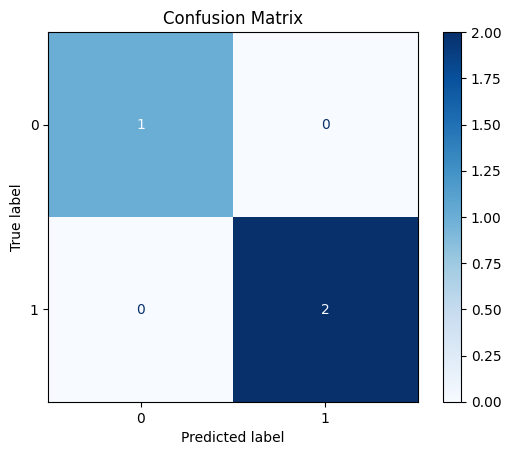

In [8]:
# Confusion metrics
# generate Confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display Confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

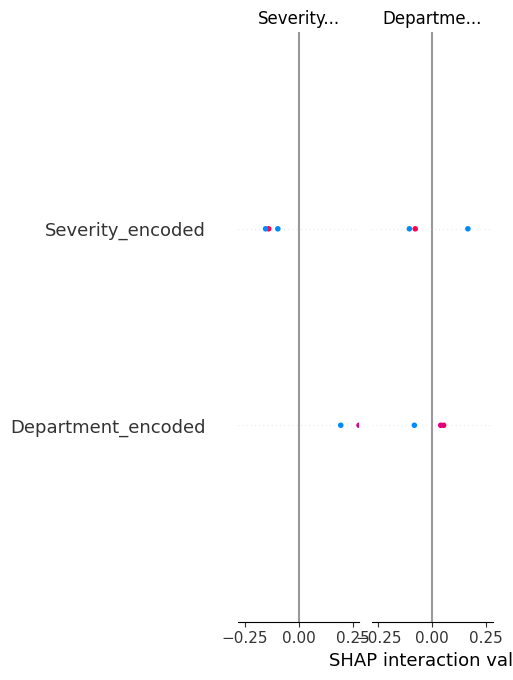

In [9]:
# Use SHAP or LIME to explain why the model predicts a CAPA as ineffective.
# Example: “Root cause = SOP gap + closure time > 45 days → high risk of rework.”

import shap
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(x_test)
shap.summary_plot(shap_values, x_test)

### 3. Predicting CAPA Effectiveness for New Data

### 4. Predicting CAPA Effectiveness for 'QA' Department

In [22]:
# Filter the original DataFrame for 'QA' department
qa_df = df[df['Department'] == 'QA'].copy()

# Prepare features for the 'QA' department data
qa_features = qa_df[['Severity_encoded', 'Department_encoded', 'Closure_Time_Days', 'Overdue_encoded']]

# Make predictions using the trained model
qa_predictions = model.predict(qa_features)

# Add predictions to the 'QA' DataFrame for easy viewing
qa_df['Predicted_CAPA_Effectiveness'] = qa_predictions
qa_df['Predicted_CAPA_Effectiveness_Label'] = qa_df['Predicted_CAPA_Effectiveness'].apply(lambda x: 'Effective' if x == 1 else 'Ineffective')

# Display the results for the 'QA' department
print("Predictions for 'QA' Department:")
display(qa_df[['CAPA_ID', 'Severity', 'Closure_Time_Days', 'Overdue', 'Predicted_CAPA_Effectiveness_Label']])

Predictions for 'QA' Department:


,CAPA_ID,Severity,Closure_Time_Days,Overdue,Predicted_CAPA_Effectiveness_Label
2,CAPA-003,Minor,20,No,Effective
5,CAPA-006,Minor,15,No,Effective
8,CAPA-009,Minor,25,No,Effective
11,CAPA-012,Minor,18,No,Effective
14,CAPA-015,Minor,22,No,Effective


### Predict CAPA Effectiveness for a User-Specified Department

In [23]:
from ipywidgets import interact, Dropdown, Output
from IPython.display import display

# Get unique department names from the original DataFrame
available_departments = df['Department'].unique().tolist()

def predict_for_department(selected_department):
    # Filter the original DataFrame for the selected department
    department_df = df[df['Department'] == selected_department].copy()

    if department_df.empty:
        print(f"No CAPAs found for the department: {selected_department}")
        return

    #features for the selected department data
    # already encoded columns from the original df

    department_features = department_df[['Severity_encoded', 'Department_encoded', 'Closure_Time_Days', 'Overdue_encoded']]

    # Make predictions using the trained model
    department_predictions = model.predict(department_features)

    # Add predictions to the DataFrame for easy viewing
    department_df['Predicted_CAPA_Effectiveness'] = department_predictions
    department_df['Predicted_CAPA_Effectiveness_Label'] = department_df['Predicted_CAPA_Effectiveness'].apply(lambda x: 'Effective' if x == 1 else 'Ineffective')

    # Display the results for the selected department
    print(f"Predictions for '{selected_department}' Department:")
    display(department_df[['CAPA_ID', 'Severity', 'Closure_Time_Days', 'Overdue', 'Predicted_CAPA_Effectiveness_Label']])

# Create a dropdown widget for department selection
department_dropdown = Dropdown(
    options=available_departments,
    description='Select Department:',
    disabled=False,
)

# Use interact to link the dropdown to the prediction function
interact(predict_for_department, selected_department=department_dropdown);


interactive(children=(Dropdown(description='Select Department:', options=('Warehouse', 'Production', 'QA', 'Pa…